# 04. Front-end: kecepatan menggambar grafik EKG live

**Tujuan.** Membandingkan empat cara menggambar sinyal EKG yang bergeser terus: Canvas 2D (tulis sendiri), uPlot, Chart.js, dan SVG. Sinyal yang digambar adalah data MIT-BIH asli (250 Hz, terfilter, dari notebook 00).

**Pembanding.** Versi 1 hanya membandingkan Canvas, Chart.js, dan SVG. Sekarang ditambah uPlot, library berbasis canvas yang memang dibuat untuk data deret waktu. uPlot: TODO: verifikasi sumber (rujukan resmi untuk klaim kinerja).

**Cara ukur.**
- Tiap frame menggeser jendela sinyal 4 sampel, lalu menggambar ulang `N` titik pada area 1200 x 300 px. 2.500 titik setara 10 detik satu pasien pada 250 Hz.
- Dua metrik per frame: `work` (waktu JavaScript untuk menyiapkan dan menggambar) dan `dt` (selisih timestamp `requestAnimationFrame` antar frame, yang ikut menangkap biaya raster dan komposit).
- Frame terlambat: `dt` lebih dari 16,7 ms ditambah toleransi 1 ms untuk jitter vsync.
- Pemanasan 30 frame. Tiap kombinasi diulang beberapa kali di halaman baru. Urutan kombinasi diacak per ulangan (seed tetap) supaya efek pemanasan CPU/termal tidak menguntungkan satu library. Dilaporkan median antar ulangan dengan IQR dan interval kepercayaan 95% (bootstrap).
- Dua kondisi: **headless** (frame rate limit dimatikan, jadi `dt` mendekati biaya murni) dan **headed** (jendela Chromium biasa, GPU aktif, vsync menyala, seperti pengguna sebenarnya).

**Keadilan.** Semua library tanpa sumbu, legend, atau tooltip pada perbandingan utama (yang diukur adalah pekerjaan inti menggambar garis). Varian `uplot_axes` dan `chartjs_axes` ditambahkan supaya biaya sumbu juga terlihat. Chart.js menyimpan data sebagai objek `{x, y}` dan nilainya diperbarui tiap frame, karena itulah format datanya (biaya itu ikut terhitung). uPlot menerima `Float32Array` tanpa salinan.

**Keterbatasan.** Satu mesin, satu browser (Chromium), satu ukuran kanvas. Hasil di Firefox, Safari, atau perangkat seluler bisa berbeda.

In [1]:
import sys, json, pathlib, threading, http.server, functools, random, time, asyncio
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from playwright.async_api import async_playwright
from bench import env, plotstyle, stats
from bench.plotstyle import ST
random.seed(0); np.random.seed(0)
QUICK = False                       # True: 2 ulangan x 1 detik (uji coba, sekitar 3 menit)
REPS, DUR = (2, 1000) if QUICK else (5, 2500)
SIZES = [1250, 2500, 5000, 10000, 20000, 40000]
MODES = ["canvas", "uplot", "chartjs", "svg", "uplot_axes", "chartjs_axes"]
LABEL = {"canvas": "Canvas 2D", "uplot": "uPlot", "chartjs": "Chart.js", "svg": "SVG",
         "uplot_axes": "uPlot + sumbu", "chartjs_axes": "Chart.js + sumbu"}
LATE_MS = 16.7 + 1.0
FE = ROOT/"bench/fe"
e = env.info(["playwright"]); e["quick"] = QUICK; e["reps"] = REPS; e["dur_ms"] = DUR
e["npm_chart.js"] = json.load(open(FE/"node_modules/chart.js/package.json"))["version"]
e["npm_uplot"] = json.load(open(FE/"node_modules/uplot/package.json"))["version"]
pd.Series(e, name="nilai").to_frame()

,nilai
cpu,Apple M2
inti_fisik,8
inti_logis,8
ram_gb,16.0
os,macOS-27.0.1-arm64-arm-64bit
python,3.11.15
playwright,1.47.0
quick,False
reps,5
dur_ms,2500


## 1. Jalankan benchmark

In [2]:
class Q(http.server.SimpleHTTPRequestHandler):
    def log_message(self, *a): pass
srv = http.server.ThreadingHTTPServer(("127.0.0.1", 0), functools.partial(Q, directory=str(FE)))
threading.Thread(target=srv.serve_forever, daemon=True).start()
URL = f"http://127.0.0.1:{srv.server_address[1]}/page.html"

async def run_env(p, headless):
    args = ["--disable-frame-rate-limit", "--disable-gpu-vsync"] if headless else []
    b = await p.chromium.launch(headless=headless, args=args)
    info = {"chromium": b.version}
    combos = [(m, n) for m in MODES for n in SIZES]; rows = []
    for rep in range(REPS):
        random.shuffle(combos)
        for m, n in combos:
            pg = await b.new_page(viewport={"width": 1250, "height": 400})
            await pg.goto(URL); await pg.evaluate("loadSignal()")
            if "gpu" not in info: info["gpu"] = await pg.evaluate("gpu()")
            r = await pg.evaluate(f"runBench('{m}',{n},{DUR})"); await pg.close()
            dt, w = np.array(r["dt"]), np.array(r["work"])
            rows.append({"env": "headless" if headless else "headed", "mode": m, "n": n, "rep": rep, "frames": len(dt),
                         "dt_median": np.median(dt), "dt_p95": np.percentile(dt, 95), "dt_p99": np.percentile(dt, 99),
                         "work_median": np.median(w), "work_p95": np.percentile(w, 95),
                         "late_frac": float((dt > LATE_MS).mean()), "fps": 1000/dt.mean()})
    await b.close(); return rows, info

async def main():
    async with async_playwright() as p:
        out, infos = [], {}
        for hl in (True, False):
            t = time.time(); rows, infos["headless" if hl else "headed"] = await run_env(p, hl); out += rows
            print("headless" if hl else "headed", "selesai dalam", round(time.time()-t), "detik")
    return out, infos
rows, infos = await main()
raw = pd.DataFrame(rows); raw.to_csv(ROOT/"results/04_fe_raw.csv", index=False)
json.dump(infos, open(ROOT/"results/04_fe_env.json", "w"), indent=1); infos

headless selesai dalam 516 detik


headed selesai dalam 515 detik


{'headless': {'chromium': '129.0.6668.29',
  'gpu': 'ANGLE (Apple, Apple M2, OpenGL 4.1)'},
 'headed': {'chromium': '129.0.6668.29',
  'gpu': 'ANGLE (Apple, ANGLE Metal Renderer: Apple M2, Unspecified Version)'}}

## 2. Ringkasan

Tabel: median antar ulangan, dengan IQR dan interval kepercayaan 95% bootstrap (hanya 5 ulangan, jadi interval ini kasar). `work` adalah waktu JavaScript per frame, `dt` adalah jarak antar frame, `late` adalah persen frame yang lebih lambat dari 16,7 ms (+1 ms).

In [3]:
raw = pd.read_csv(ROOT/"results/04_fe_raw.csv")
rows = []
for (en, m, n), g in raw.groupby(["env", "mode", "n"]):
    w, d, l = stats.summ(g.work_median), stats.summ(g.dt_median), g.late_frac.median()
    rows.append({"env": en, "library": LABEL[m], "n": n, "work_ms": w["median"], "work_iqr": f'{w["q1"]:.2f}-{w["q3"]:.2f}',
                 "work_ci95": f'{w["ci_lo"]:.2f}-{w["ci_hi"]:.2f}', "dt_ms": d["median"], "dt_p99_ms": g.dt_p99.median(),
                 "late_%": 100*l, "fps": g.fps.median()})
S = pd.DataFrame(rows); S.to_csv(ROOT/"results/04_fe_ringkasan.csv", index=False)
pd.set_option("display.width", 200)
for en in ("headless", "headed"):
    print(f"== {en} =="); display(S[(S.env == en) & ~S.library.str.contains("sumbu")].pivot(index="n", columns="library", values="work_ms").round(2)
                                  [["Canvas 2D", "uPlot", "Chart.js", "SVG"]])

== headless ==


library,Canvas 2D,uPlot,Chart.js,SVG
n,,,,
1250,0.1,0.2,0.7,0.8
2500,0.2,0.3,1.0,1.4
5000,0.4,0.4,1.0,2.2
10000,0.7,0.7,1.6,4.1
20000,1.3,1.0,2.8,8.5
40000,2.3,1.9,3.9,15.2


== headed ==


library,Canvas 2D,uPlot,Chart.js,SVG
n,,,,
1250,0.3,0.4,2.0,0.9
2500,0.5,0.5,2.5,1.2
5000,0.6,0.9,2.9,1.4
10000,1.3,1.6,3.5,2.7
20000,1.9,1.5,4.3,5.4
40000,3.8,3.4,4.8,11.3


## 3. Grafik

Garis putus-putus horizontal menandai 16,7 ms (batas 60 fps).

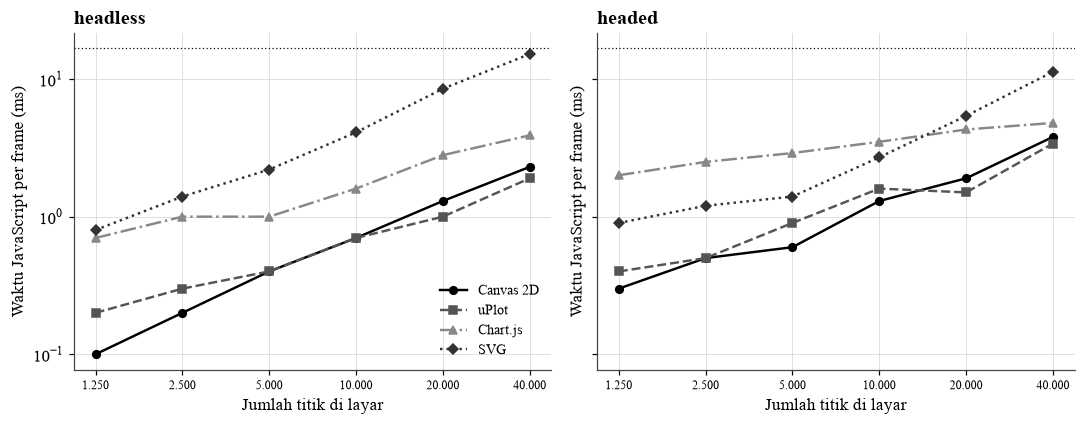

In [4]:
S = pd.read_csv(ROOT/"results/04_fe_ringkasan.csv")
def panel(ax, en, col, libs, ylab, hline=True):
    for lib, st in zip(libs, ST):
        s = S[(S.env == en) & (S.library == lib)].sort_values("n")
        ax.plot(s.n, s[col], label=lib, lw=1.6, ms=5, **st)
    if hline: ax.axhline(16.7, color="#000", lw=.8, ls=(0, (1, 2)))
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels([f"{n:,}".replace(",", ".") for n in SIZES], fontsize=8)
    ax.minorticks_off(); ax.set_xlabel("Jumlah titik di layar"); ax.set_ylabel(ylab)
main = ["Canvas 2D", "uPlot", "Chart.js", "SVG"]
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, en in zip(ax, ("headless", "headed")):
    panel(a, en, "work_ms", main, "Waktu JavaScript per frame (ms)"); a.set_title(en, loc="left", fontweight="bold")
ax[0].legend(frameon=False, fontsize=9); fig.tight_layout(); fig.savefig(ROOT/"grafik/04_fe_work.png"); plt.show()

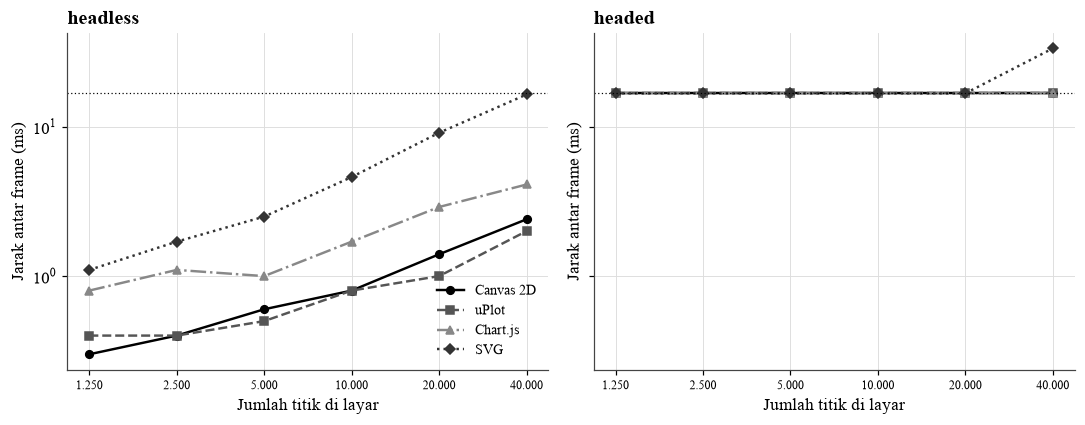

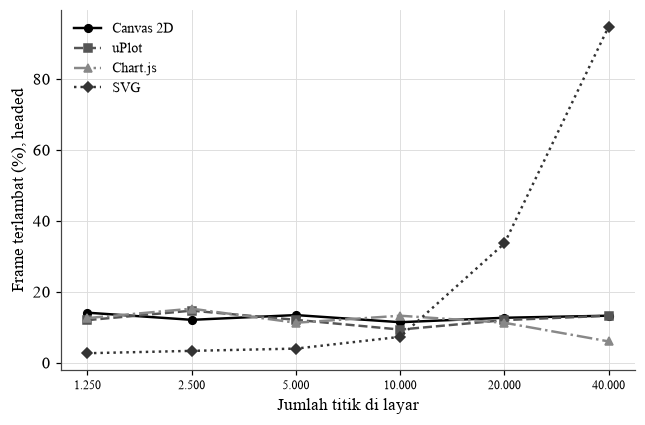

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for a, en in zip(ax, ("headless", "headed")):
    panel(a, en, "dt_ms", main, "Jarak antar frame (ms)"); a.set_title(en, loc="left", fontweight="bold")
ax[0].legend(frameon=False, fontsize=9); fig.tight_layout(); fig.savefig(ROOT/"grafik/04_fe_dt.png"); plt.show()
fig, ax = plt.subplots(figsize=(6, 4))
for lib, st in zip(main, ST):
    s = S[(S.env == "headed") & (S.library == lib)].sort_values("n"); ax.plot(s.n, s["late_%"], label=lib, lw=1.6, ms=5, **st)
ax.set_xscale("log"); ax.set_xticks(SIZES); ax.set_xticklabels([f"{n:,}".replace(",", ".") for n in SIZES], fontsize=8); ax.minorticks_off()
ax.set_xlabel("Jumlah titik di layar"); ax.set_ylabel("Frame terlambat (%), headed"); ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(ROOT/"grafik/04_fe_terlambat.png"); plt.show()

## 4. Biaya sumbu (uPlot dan Chart.js dengan dan tanpa sumbu)

In [6]:
X = S[(S.n.isin([2500, 10000, 40000]))].pivot_table(index=["env", "n"], columns="library", values="work_ms").round(2)
X[["uPlot", "uPlot + sumbu", "Chart.js", "Chart.js + sumbu"]]

library         uPlot  uPlot + sumbu  Chart.js  Chart.js + sumbu
env      n                                                      
headed   2500     0.5            0.9       2.5               3.3
         10000    1.6            1.4       3.5               4.0
         40000    3.4            2.9       4.8               5.0
headless 2500     0.3            0.5       1.0               1.3
         10000    0.7            0.8       1.6               1.7
         40000    1.9            2.1       3.9               3.5

## 5. Pembacaan otomatis pada 2.500 titik (10 detik, satu pasien) dan 40.000 titik

In [7]:
for en in ("headless", "headed"):
    for n in (2500, 40000):
        s = S[(S.env == en) & (S.n == n) & ~S.library.str.contains("sumbu")].sort_values("work_ms")
        print(f"{en:9s} n={n:6d}: " + " < ".join(f"{r.library} {r.work_ms:.2f} ms (terlambat {r['late_%']:.0f}%)" for _, r in s.iterrows()))

headless  n=  2500: Canvas 2D 0.20 ms (terlambat 0%) < uPlot 0.30 ms (terlambat 0%) < Chart.js 1.00 ms (terlambat 0%) < SVG 1.40 ms (terlambat 0%)
headless  n= 40000: uPlot 1.90 ms (terlambat 0%) < Canvas 2D 2.30 ms (terlambat 0%) < Chart.js 3.90 ms (terlambat 0%) < SVG 15.20 ms (terlambat 22%)
headed    n=  2500: Canvas 2D 0.50 ms (terlambat 12%) < uPlot 0.50 ms (terlambat 15%) < SVG 1.20 ms (terlambat 3%) < Chart.js 2.50 ms (terlambat 15%)
headed    n= 40000: uPlot 3.40 ms (terlambat 13%) < Canvas 2D 3.80 ms (terlambat 13%) < Chart.js 4.80 ms (terlambat 6%) < SVG 11.30 ms (terlambat 95%)



## Kesimpulan notebook 04

Dibaca dari tabel dan grafik di atas (5 ulangan, Chromium 129, Apple M2, GPU Apple M2 lewat ANGLE/Metal pada kondisi headed).

- **Pada beban nyata (2.500 titik, 10 detik satu pasien), semua library jauh di bawah 16,7 ms.** Waktu JavaScript per frame: Canvas 2D 0,5 ms, uPlot 0,5 ms, SVG 1,2 ms, Chart.js 2,5 ms (headed). Kecepatan menggambar bukan faktor penentu pada ukuran ini.
- **Perbedaan baru terlihat pada puluhan ribu titik.** Pada 40.000 titik: SVG 11,3 ms (headed) dan 15,2 ms (headless), hampir menyentuh batas frame, dan 95% frame terlambat di headed. Canvas 2D, uPlot, dan Chart.js tetap di bawah 5 ms.
- **Canvas 2D tulis sendiri tidak lebih cepat dari uPlot secara berarti** (3,8 ms vs 3,4 ms pada 40.000 titik, headed; selisihnya di dalam sebaran antar ulangan). Pilihan Canvas pada versi 1 tidak bisa dibenarkan oleh kecepatan saja. Alasan yang tersisa untuk Canvas tulis sendiri hanya kontrol penuh dan tanpa dependensi. Alasan untuk uPlot: sumbu, skala, dan interaksi (zoom) sudah tersedia dengan biaya yang hampir sama. Biaya menambah sumbu pada uPlot kecil (sekitar 0,4 ms pada 2.500 titik), pada Chart.js sekitar 0,8 ms.
- **Chart.js** paling lambat di antara tiga library canvas, tetapi masih di bawah 5 ms sampai 40.000 titik pada mesin ini.

**Hal yang perlu diwaspadai**
- Persen frame terlambat pada kondisi headed memakai ambang 16,7 ms + 1 ms. Karena vsync berjitter, semua library menunjukkan sekitar 10 sampai 14% frame terlambat bahkan pada beban ringan. Angka itu hanya bermakna untuk SVG pada 20.000 dan 40.000 titik (34% dan 95%). Jangan dibaca sebagai selisih antar library di bawah itu.
- Pengukuran pertama uPlot sempat keliru (0,0 ms) karena uPlot menggambar di microtask yang lolos dari timer. Diperbaiki dengan `u.batch()` (gambar sinkron) di `bench/fe/page.html`, lalu uji diulang penuh.
- Waktu JavaScript tidak mencakup raster GPU. Biaya itu hanya terlihat lewat jarak antar frame, yang pada headed terkunci vsync 16,7 ms, jadi raster belum terbukti tidak jadi masalah pada beban berat.
- Satu mesin, satu browser (Chromium 129), satu ukuran kanvas, tanpa perangkat seluler. Skenario yang diukur hanya satu pasien per grafik. Dashboard multi-pasien (banyak grafik sekaligus) belum diuji.
